In [2]:

# ============================================================
# GUÍA 4 - PARTE I
# TERMÓMETRO DE REZAGO CATASTRAL
# DIAGNÓSTICO DE CALIDAD - BASE RAW DE COMPRAVENTAS
# Periodo: 2015-2023 | Piloto AMB
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# 0. CARGA Y VALIDACIÓN INICIAL
# ------------------------------------------------------------

archivo = Path("Registro_de_transacciones_base.csv")

# Se conserva la estructura original.
# Se leen inicialmente los campos como texto para evitar
# conversiones automáticas que alteren identificadores.

df_raw = pd.read_csv(
    archivo,
    dtype="string",
    low_memory=False,
    encoding="utf-8-sig"
)

# Normalización de nombres de columnas
# Elimina espacios y convierte los nombres a minúsculas
df_raw.columns = (
    df_raw.columns
    .str.strip()
    .str.lower()
)

print("Columnas normalizadas:")
print(df_raw.columns.tolist())

columnas_originales = df_raw.columns.tolist()

print("=" * 65)
print("1. CARACTERIZACIÓN GENERAL - BASE RAW")
print("=" * 65)

print("Registros:", len(df_raw))
print("Columnas:", len(df_raw.columns))
print("Dimensiones:", df_raw.shape)

if len(df_raw) != 165517:
    print("ATENCIÓN: El número de registros difiere de 165.517")

if len(df_raw.columns) != 26:
    print("ATENCIÓN: La estructura difiere de las 26 columnas esperadas")

columnas_requeridas = [
    "pk", "matricula", "orip", "num_anotacion",
    "fecha_radica_texto", "year_radica",
    "divipola", "departamento", "municipio",
    "cod_natujur", "nombre_natujur", "valor"
]

faltantes_estructura = [
    c for c in columnas_requeridas
    if c not in df_raw.columns
]

if faltantes_estructura:
    raise ValueError(
        f"Faltan columnas esperadas: {faltantes_estructura}"
    )

perfil = pd.DataFrame({
    "Variable": df_raw.columns,
    "Tipo": df_raw.dtypes.astype(str).values,
    "Nulos": df_raw.isna().sum().values,
    "% Nulos": (df_raw.isna().mean() * 100).round(2).values,
    "Valores únicos": [
        df_raw[c].nunique(dropna=True)
        for c in df_raw.columns
    ]
})

display(perfil)

# ------------------------------------------------------------
# 2. COMPLETITUD
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("2. COMPLETITUD")
print("=" * 65)

completitud = perfil[
    ["Variable", "Nulos", "% Nulos"]
].sort_values("% Nulos", ascending=False)

display(completitud)

print("Total de celdas nulas:", df_raw.isna().sum().sum())
print(
    "Columnas con valores nulos:",
    (df_raw.isna().sum() > 0).sum()
)

variables_criticas = [
    "pk", "matricula", "orip", "num_anotacion",
    "fecha_radica_texto", "municipio",
    "cod_natujur", "valor"
]

print("\nCOMPLETITUD DE VARIABLES CRÍTICAS")
display(
    completitud[
        completitud["Variable"].isin(variables_criticas)
    ]
)

# ------------------------------------------------------------
# 3. VARIABLES AUXILIARES PARA EL DIAGNÓSTICO
# No se modifica la base RAW.
# ------------------------------------------------------------

df = df_raw.copy()

# Identificador compuesto del inmueble
df["id_inmueble"] = (
    df["orip"].str.strip()
    + "-"
    + df["matricula"].str.strip()
)

# Fechas: interpretar formato ISO y formato DD/MM/AA
# Se da prioridad explícita al formato ISO.
texto_fecha = df["fecha_radica_texto"].str.strip()

fecha_iso = pd.to_datetime(
    texto_fecha,
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

fecha_iso_corta = pd.to_datetime(
    texto_fecha,
    format="%Y-%m-%d",
    errors="coerce"
)

fecha_dmy = pd.to_datetime(
    texto_fecha,
    format="%d/%m/%y",
    errors="coerce"
)

fecha_dmy_larga = pd.to_datetime(
    texto_fecha,
    format="%d/%m/%Y",
    errors="coerce"
)

df["fecha_analisis"] = (
    fecha_iso
    .fillna(fecha_iso_corta)
    .fillna(fecha_dmy)
    .fillna(fecha_dmy_larga)
)

df["anio_analisis"] = df["fecha_analisis"].dt.year
df["mes_analisis"] = df["fecha_analisis"].dt.month

df["year_num"] = pd.to_numeric(
    df["year_radica"], errors="coerce"
)

# Conversión monetaria auxiliar
# La fuente usa comas como separadores de miles.
df["valor_num"] = pd.to_numeric(
    df["valor"]
    .str.replace(",", "", regex=False)
    .str.replace("$", "", regex=False)
    .str.strip(),
    errors="coerce"
)

# ------------------------------------------------------------
# 4. GRANULARIDAD Y VENTAS REPETIDAS POTENCIALES
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("3. GRANULARIDAD Y REPETICIÓN TEMPORAL")
print("=" * 65)

frecuencia_inmuebles = (
    df.groupby("id_inmueble", dropna=False)
    .agg(
        registros=("pk", "size"),
        anios_distintos=("anio_analisis", "nunique"),
        fechas_distintas=("fecha_analisis", "nunique")
    )
)

resumen_granularidad = pd.DataFrame({
    "Indicador": [
        "Registros totales",
        "Identificadores de inmueble distintos",
        "Inmuebles con un registro",
        "Inmuebles con 2 o más registros",
        "Inmuebles con 2 o más fechas distintas",
        "Inmuebles con registros en 2 o más años",
        "Máximo de registros por inmueble"
    ],
    "Resultado": [
        len(df),
        df["id_inmueble"].nunique(dropna=True),
        (frecuencia_inmuebles["registros"] == 1).sum(),
        (frecuencia_inmuebles["registros"] >= 2).sum(),
        (frecuencia_inmuebles["fechas_distintas"] >= 2).sum(),
        (frecuencia_inmuebles["anios_distintos"] >= 2).sum(),
        frecuencia_inmuebles["registros"].max()
    ]
})

display(resumen_granularidad)

# Estos son candidatos potenciales, no pares válidos
# del índice de ventas repetidas.

# ------------------------------------------------------------
# 5. FIDELIDAD Y EXACTITUD DE VALORES
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("4. FIDELIDAD DE VALORES MONETARIOS")
print("=" * 65)

v = df["valor_num"]
v_pos = v[v > 0]

resumen_valores = pd.DataFrame({
    "Indicador": [
        "Total de registros",
        "Valores nulos en origen",
        "Valores no interpretables adicionales",
        "Valores iguales a cero",
        "Valores negativos",
        "Valores positivos",
        "Valor mínimo positivo",
        "Percentil 25 positivo",
        "Mediana positiva",
        "Percentil 75 positivo",
        "Percentil 99 positivo",
        "Valor máximo positivo"
    ],
    "Resultado": [
        len(df),
        df_raw["valor"].isna().sum(),
        (v.isna() & df_raw["valor"].notna()).sum(),
        (v == 0).sum(),
        (v < 0).sum(),
        (v > 0).sum(),
        v_pos.min(),
        v_pos.quantile(0.25),
        v_pos.median(),
        v_pos.quantile(0.75),
        v_pos.quantile(0.99),
        v_pos.max()
    ]
})

display(resumen_valores)

print("\nNATURALEZAS JURÍDICAS PRESENTES")

naturalezas = (
    df.groupby(
        ["cod_natujur", "nombre_natujur"],
        dropna=False
    )
    .agg(
        registros=("pk", "size"),
        valores_cero=("valor_num", lambda x: (x == 0).sum())
    )
    .reset_index()
    .sort_values("registros", ascending=False)
)

naturalezas["% valores cero"] = (
    naturalezas["valores_cero"]
    / naturalezas["registros"] * 100
).round(2)

display(naturalezas.head(20))

# ------------------------------------------------------------
# 6. INTEGRIDAD Y UNICIDAD
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("5. INTEGRIDAD Y UNICIDAD")
print("=" * 65)

clave_registral = [
    "orip", "matricula", "num_anotacion"
]

duplicados_clave = df_raw.duplicated(
    subset=clave_registral,
    keep=False
)

grupos_clave = (
    df_raw.groupby(clave_registral, dropna=False)
    .size()
)

resumen_integridad = pd.DataFrame({
    "Indicador": [
        "PK faltantes",
        "PK repetidas",
        "Matrículas faltantes",
        "ORIP faltantes",
        "Números de anotación faltantes",
        "Filas exactamente duplicadas",
        "Registros con clave registral repetida",
        "Grupos con clave registral repetida"
    ],
    "Resultado": [
        df_raw["pk"].isna().sum(),
        df_raw["pk"].duplicated(keep=False).sum(),
        df_raw["matricula"].isna().sum(),
        df_raw["orip"].isna().sum(),
        df_raw["num_anotacion"].isna().sum(),
        df_raw.duplicated().sum(),
        duplicados_clave.sum(),
        (grupos_clave > 1).sum()
    ]
})

display(resumen_integridad)

print("\nEJEMPLOS DE CLAVES REGISTRALES REPETIDAS")
display(
    df_raw.loc[
        duplicados_clave,
        [
            "pk", "orip", "matricula",
            "num_anotacion", "fecha_radica_texto",
            "nombre_natujur"
        ]
    ].head(10)
)

# ------------------------------------------------------------
# 7. COBERTURA TEMPORAL Y TERRITORIAL
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("6. COBERTURA TEMPORAL Y TERRITORIAL")
print("=" * 65)

inconsistencias_anio = (
    df["fecha_analisis"].notna()
    & df["year_num"].notna()
    & (df["anio_analisis"] != df["year_num"])
)

resumen_temporal = pd.DataFrame({
    "Indicador": [
        "Fechas nulas en origen",
        "Fechas no interpretables adicionales",
        "Inconsistencias entre fecha y year_radica",
        "Fecha mínima",
        "Fecha máxima",
        "Años distintos",
        "Meses distintos"
    ],
    "Resultado": [
        df_raw["fecha_radica_texto"].isna().sum(),
        (
            df["fecha_analisis"].isna()
            & df_raw["fecha_radica_texto"].notna()
        ).sum(),
        inconsistencias_anio.sum(),
        df["fecha_analisis"].min(),
        df["fecha_analisis"].max(),
        df["anio_analisis"].nunique(),
        df["mes_analisis"].nunique()
    ]
})

display(resumen_temporal)

registros_anio = (
    df.groupby("anio_analisis", dropna=False)
    .size()
    .reset_index(name="Registros")
    .sort_values("anio_analisis")
)

print("\nREGISTROS POR AÑO")
display(registros_anio)

registros_municipio = (
    df.groupby(["divipola", "municipio"], dropna=False)
    .size()
    .reset_index(name="Registros")
    .sort_values("Registros", ascending=False)
)

print("\nREGISTROS POR MUNICIPIO")
display(registros_municipio)

print("\nCOBERTURA AÑO-MUNICIPIO")
cobertura = pd.crosstab(
    df["anio_analisis"],
    df["municipio"]
)

display(cobertura)

municipios_esperados = {
    "68001": "BUCARAMANGA",
    "68276": "FLORIDABLANCA",
    "68307": "GIRÓN",
    "68547": "PIEDECUESTA"
}

codigos_observados = df["divipola"].str.strip()

print(
    "\nRegistros con DIVIPOLA fuera del piloto:",
    (~codigos_observados.isin(municipios_esperados)).sum()
)

# ------------------------------------------------------------
# 8. CLARIDAD Y CONSISTENCIA DE CÓDIGOS
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("7. CLARIDAD Y CONSISTENCIA DE CÓDIGOS")
print("=" * 65)

codigos_juridicos = (
    df.groupby("cod_natujur", dropna=False)["nombre_natujur"]
    .nunique(dropna=False)
)

codigos_territoriales = (
    df.groupby("divipola", dropna=False)["municipio"]
    .nunique(dropna=False)
)

resumen_codigos = pd.DataFrame({
    "Indicador": [
        "Códigos jurídicos distintos",
        "Descripciones jurídicas distintas",
        "Códigos jurídicos con varias descripciones",
        "Códigos DIVIPOLA distintos",
        "DIVIPOLA con varios nombres de municipio"
    ],
    "Resultado": [
        df["cod_natujur"].nunique(),
        df["nombre_natujur"].nunique(),
        (codigos_juridicos > 1).sum(),
        df["divipola"].nunique(),
        (codigos_territoriales > 1).sum()
    ]
})

display(resumen_codigos)

print("\nTIPOS DE DATOS EN EL ARCHIVO RAW")
print(
    "Los campos se importaron como texto para preservar "
    "su representación original."
)

display(
    df_raw[
        [
            "pk", "matricula", "orip",
            "num_anotacion", "fecha_radica_texto",
            "cod_natujur", "nombre_natujur", "valor"
        ]
    ].dtypes.to_frame("Tipo importado")
)

print("\nDIAGNÓSTICO FINALIZADO")
print("Registros originales conservados:", len(df_raw))


Columnas normalizadas:
['pk', 'matricula', 'fecha_radica_texto', 'fecha_apertura_texto', 'year_radica', 'orip', 'divipola', 'departamento', 'municipio', 'tipo_predio_zona', 'categoria_ruralidad', 'num_anotacion', 'estado_folio', 'folios_derivados', 'dinámica_inmobiliaria', 'cod_natujur', 'nombre_natujur', 'numero_catastral', 'numero_catastral_antiguo', 'documento_justificativo', 'count_a', 'count_de', 'predios_nuevos', 'tiene_valor', 'tiene_mas_de_un_valor', 'valor']
1. CARACTERIZACIÓN GENERAL - BASE RAW
Registros: 165517
Columnas: 26
Dimensiones: (165517, 26)


,Variable,Tipo,Nulos,% Nulos,Valores únicos
0,pk,string,0,0.00,165517
1,matricula,string,0,0.00,139909
2,fecha_radica_texto,string,0,0.00,2198
3,fecha_apertura_texto,string,133948,80.93,9454
4,year_radica,string,0,0.00,9
5,orip,string,0,0.00,2
6,divipola,string,0,0.00,4
7,departamento,string,0,0.00,1
8,municipio,string,0,0.00,4
9,tipo_predio_zona,string,0,0.00,3



2. COMPLETITUD


,Variable,Nulos,% Nulos
18,numero_catastral_antiguo,165517,100.00
17,numero_catastral,165517,100.00
13,folios_derivados,165508,99.99
3,fecha_apertura_texto,133948,80.93
1,matricula,0,0.00
5,orip,0,0.00
6,divipola,0,0.00
2,fecha_radica_texto,0,0.00
4,year_radica,0,0.00
0,pk,0,0.00


Total de celdas nulas: 630490
Columnas con valores nulos: 4

COMPLETITUD DE VARIABLES CRÍTICAS


,Variable,Nulos,% Nulos
1,matricula,0,0.0
5,orip,0,0.0
2,fecha_radica_texto,0,0.0
0,pk,0,0.0
8,municipio,0,0.0
11,num_anotacion,0,0.0
15,cod_natujur,0,0.0
25,valor,0,0.0


... (19 outputs left out)

,Indicador,Resultado
0,Códigos jurídicos distintos,1
1,Descripciones jurídicas distintas,1
2,Códigos jurídicos con varias descripciones,0
3,Códigos DIVIPOLA distintos,4
4,DIVIPOLA con varios nombres de municipio,0



TIPOS DE DATOS EN EL ARCHIVO RAW
Los campos se importaron como texto para preservar su representación original.


,Tipo importado
pk,string
matricula,string
orip,string
num_anotacion,string
fecha_radica_texto,string
cod_natujur,string
nombre_natujur,string
valor,string



DIAGNÓSTICO FINALIZADO
Registros originales conservados: 165517


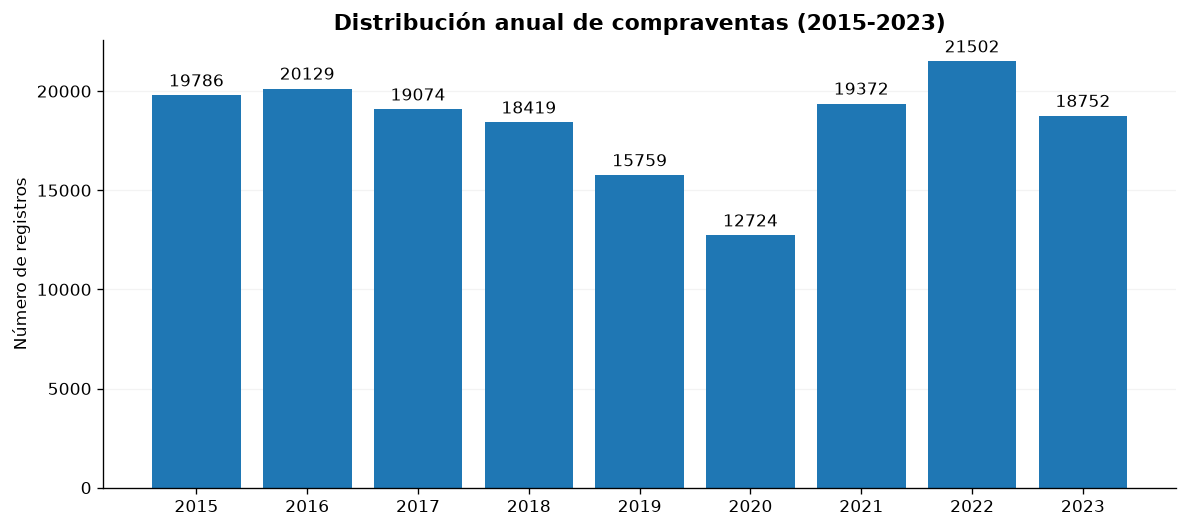

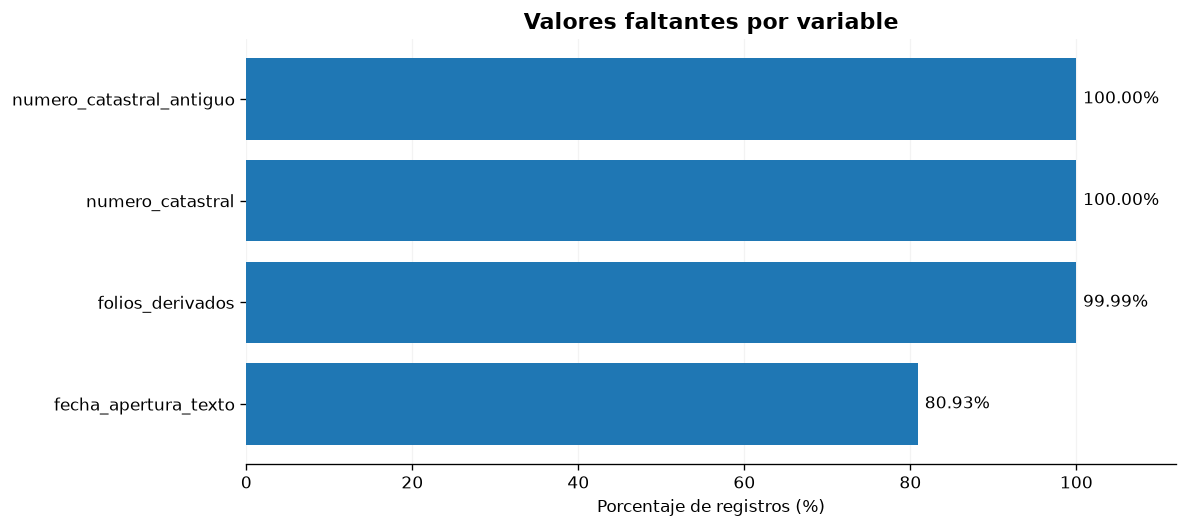

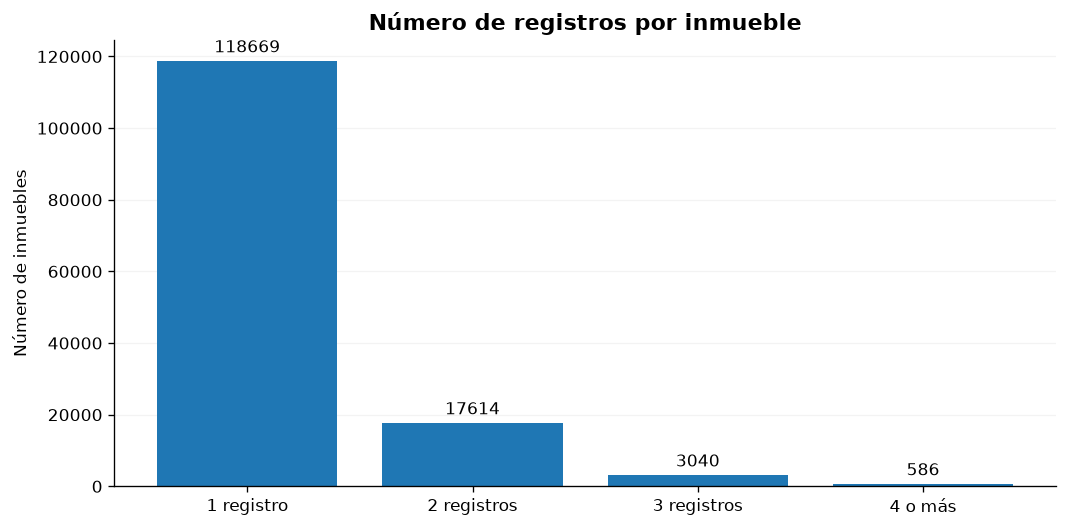

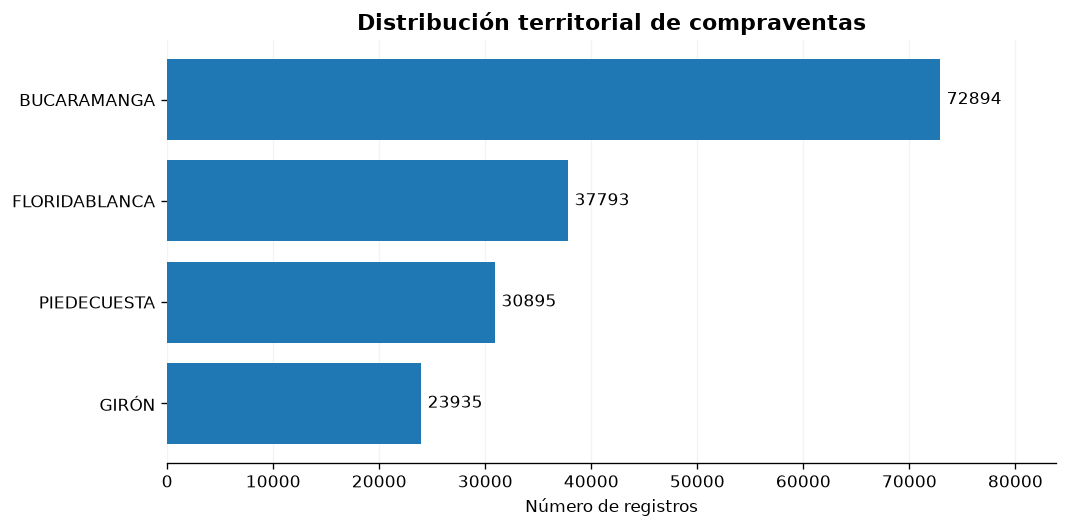


Figuras guardadas en:
C:\Users\User\Documents\Magister\Gerencia\Entrega 4\graficas_parte_1


In [3]:

# ============================================================
# GRÁFICAS - PARTE I
# BASE RAW DE COMPRAVENTAS IGAC 2015-2023
# ============================================================

from pathlib import Path
import matplotlib.pyplot as plt

carpeta = Path("../../figuras/guia_4")
carpeta.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 10,
    "axes.titlesize": 13
})

# ------------------------------------------------------------
# FIGURA 1. DISTRIBUCIÓN ANUAL
# ------------------------------------------------------------

datos_anuales = registros_anio.dropna(
    subset=["anio_analisis"]
).copy()

fig, ax = plt.subplots(figsize=(10, 4.5))

barras = ax.bar(
    datos_anuales["anio_analisis"].astype(int).astype(str),
    datos_anuales["Registros"]
)

ax.bar_label(barras, padding=3, fmt="%d")

ax.set_title(
    "Distribución anual de compraventas (2015-2023)",
    fontweight="bold"
)
ax.set_ylabel("Número de registros")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.15)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(
    carpeta / "figura_1_distribucion_anual.png",
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# FIGURA 2. COMPLETITUD DE VARIABLES
# ------------------------------------------------------------

nulos = (
    df_raw.isna()
    .mean()
    .mul(100)
)

nulos = nulos[nulos > 0].sort_values()

if len(nulos) > 0:

    fig, ax = plt.subplots(figsize=(10, 4.5))

    barras = ax.barh(
        nulos.index,
        nulos.values
    )

    ax.bar_label(
        barras,
        labels=[f"{x:.2f}%" for x in nulos.values],
        padding=4
    )

    ax.set_title(
        "Valores faltantes por variable",
        fontweight="bold"
    )
    ax.set_xlabel("Porcentaje de registros (%)")
    ax.set_xlim(0, max(105, nulos.max() * 1.12))
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.grid(axis="x", alpha=0.15)
    ax.set_axisbelow(True)

    plt.tight_layout()
    plt.savefig(
        carpeta / "figura_2_completitud.png",
        bbox_inches="tight"
    )
    plt.show()

else:
    print("No se identificaron columnas con valores nulos.")

# ------------------------------------------------------------
# FIGURA 3. REGISTROS POR INMUEBLE
# ------------------------------------------------------------

conteo = frecuencia_inmuebles["registros"]

categorias = pd.Series({
    "1 registro": (conteo == 1).sum(),
    "2 registros": (conteo == 2).sum(),
    "3 registros": (conteo == 3).sum(),
    "4 o más": (conteo >= 4).sum()
})

fig, ax = plt.subplots(figsize=(9, 4.5))

barras = ax.bar(
    categorias.index,
    categorias.values
)

ax.bar_label(barras, padding=3, fmt="%d")

ax.set_title(
    "Número de registros por inmueble",
    fontweight="bold"
)
ax.set_ylabel("Número de inmuebles")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.15)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(
    carpeta / "figura_3_granularidad.png",
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# FIGURA 4. COMPRAVENTAS POR MUNICIPIO
# ------------------------------------------------------------

datos_municipios = registros_municipio.sort_values(
    "Registros", ascending=True
)

fig, ax = plt.subplots(figsize=(9, 4.5))

barras = ax.barh(
    datos_municipios["municipio"],
    datos_municipios["Registros"]
)

ax.bar_label(barras, padding=4, fmt="%d")

ax.set_title(
    "Distribución territorial de compraventas",
    fontweight="bold"
)
ax.set_xlabel("Número de registros")
ax.set_xlim(
    0,
    datos_municipios["Registros"].max() * 1.15
)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="x", alpha=0.15)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(
    carpeta / "figura_4_distribucion_municipal.png",
    bbox_inches="tight"
)
plt.show()

print("\nFiguras guardadas en:")
print(carpeta.resolve())
